# FITS data visualization and statistics with Astropy

`author` Julien Morin <julien.morin@umontpellier.fr>

`date` 12 Oct 2022

Reference: __[https://docs.astropy.org/en/stable/io/fits/index.html](https://docs.astropy.org/en/stable/io/fits/index.html)__
* load a FITS image w/ astropy.io.fits, display data and header
* plot image and adjust
* compute basic statistics

## Load data and retrieve information on extensions and header

In [1]:
# import and settings
#
import numpy as np
import matplotlib.pyplot as plt
#
import astropy.io.fits as pf
from astropy.visualization import astropy_mpl_style
from astropy.visualization import simple_norm
from astropy.visualization import MinMaxInterval
from astropy.visualization import hist

In [8]:
# load FITS image
hdul = pf.open('intro-iraf-files-2018-extracted/IC434R-001.fit')

# display the HDUs contained in IC434R-001.fit
hdul.info()

### ToDo: 
###  check the length and type of hdul

print(type(hdul))
print(len(hdul))

Filename: intro-iraf-files-2018-extracted/IC434R-001.fit
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      36   (1024, 1024)   int16 (rescales to uint16)   
<class 'astropy.io.fits.hdu.hdulist.HDUList'>
1


In [9]:
# ToDo: load NICMOSn4hk12010_mos.fits and check content

hdul = pf.open('intro-iraf-files-2018-extracted/NICMOSn4hk12010_mos.fits')

hdul.info()
print(type(hdul))
print(len(hdul))

Filename: intro-iraf-files-2018-extracted/NICMOSn4hk12010_mos.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     251   ()      
  1  SCI           1 ImageHDU       143   (270, 263)   float32   
  2  ERR           1 ImageHDU        71   (270, 263)   float32   
  3  DQ            1 ImageHDU        71   (270, 263)   int16   
  4  SAMP          1 ImageHDU        71   (270, 263)   int16   
  5  TIME          1 ImageHDU        71   (270, 263)   float32   
<class 'astropy.io.fits.hdu.hdulist.HDUList'>
6


In [11]:
# load FITS image and print header
hdul = pf.open('intro-iraf-files-2018-extracted/IC434R-001.fit')
print(hdul[0].header)


SIMPLE  =                    T                                                  BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     NAXIS   =                    2 /number of axes                                  NAXIS1  =                 1024 /fastest changing axis                           NAXIS2  =                 1024 /next to fastest changing axis                   BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           DATE-OBS= '2014-11-19T02:04:52' /YYYY-MM-DDThh:mm:ss observation start, UT      EXPTIME =   100.00000000000000 /Exposure time in seconds                        EXPOSURE=   100.00000000000000 /Exposure time in seconds                        SET-TEMP=  -80.000000000000000 /CCD temperature setpoint in C                   CCD-TEMP=  -79.896003723144531 /CCD temperature at start of exposure in C       XPIXSZ  =   27.000000000000000 /Pixel Wi

In [12]:
# delete variable hdul
del hdul

In [13]:
# alternatively: get header without explicitly loading the HDU in a variable beforehand
pf.getheader('intro-iraf-files-2018-extracted/IC434R-001.fit')

SIMPLE  =                    T                                                  
BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     
NAXIS   =                    2 /number of axes                                  
NAXIS1  =                 1024 /fastest changing axis                           
NAXIS2  =                 1024 /next to fastest changing axis                   
BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           
BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           
DATE-OBS= '2014-11-19T02:04:52' /YYYY-MM-DDThh:mm:ss observation start, UT      
EXPTIME =   100.00000000000000 /Exposure time in seconds                        
EXPOSURE=   100.00000000000000 /Exposure time in seconds                        
SET-TEMP=  -80.000000000000000 /CCD temperature setpoint in C                   
CCD-TEMP=  -79.896003723144531 /CCD temperature at start of exposure in C       
XPIXSZ  =   27.0000000000000

In [14]:
# load FITS image
hdul = pf.open('intro-iraf-files-2018-extracted/IC434R-001.fit')
# retrieve the value and comment of a specific keyword
print(hdul[0].header['EXPTIME'])
print(hdul[0].header.comments['EXPTIME'])

100.0
Exposure time in seconds


In [15]:
# list available keywords
print(list(hdul[0].header.keys()))

['SIMPLE', 'BITPIX', 'NAXIS', 'NAXIS1', 'NAXIS2', 'BSCALE', 'BZERO', 'DATE-OBS', 'EXPTIME', 'EXPOSURE', 'SET-TEMP', 'CCD-TEMP', 'XPIXSZ', 'YPIXSZ', 'XBINNING', 'YBINNING', 'XORGSUBF', 'YORGSUBF', 'FILTER', 'IMAGETYP', 'FOCALLEN', 'APTDIA', 'APTAREA', 'SBSTDVER', 'SWCREATE', 'SWSERIAL', 'SITELAT', 'SITELONG', 'JD', 'OBJECT', 'TELESCOP', 'INSTRUME', 'OBSERVER', 'NOTES', 'FLIPSTAT', 'SWOWNER']


## Load and display a FITS image

In [16]:
# load FITS image
hdul = pf.open('intro-iraf-files-2018-extracted/IC434R-001.fit')
# store the data in a variable
data = hdul[0].data # call by position
#data = hdul['PRIMARY'].data # call by label

In [17]:
# delete variable hdul
del hdul

In [19]:
# alternatively: get the data without explicitly loading the HDU in a variable beforehand
data = pf.getdata('intro-iraf-files-2018-extracted/IC434R-001.fit')

In [23]:
### ToDo: check data type and dimensions
print(type(data))
print(np.shape(data))

<class 'numpy.ndarray'>
(1024, 1024)


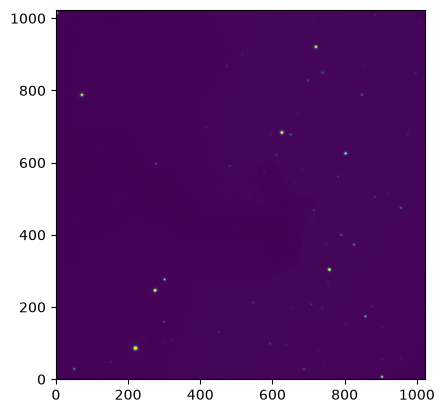

In [24]:
# plot w/ imshow
plt.figure()
im = plt.imshow(data, origin='lower') # option origin='lower' results in same orientation as ds9
plt.show()

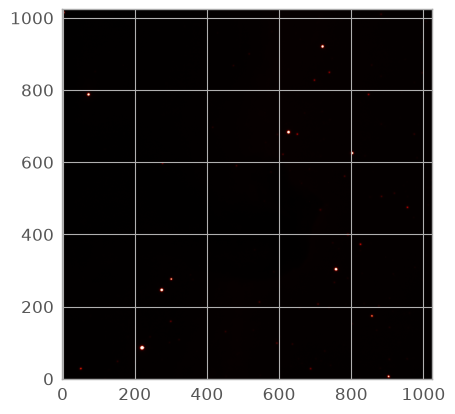

In [25]:
# optimize plot parameters for image visualization
plt.figure()
plt.style.use(astropy_mpl_style)
im = plt.imshow(data, origin='lower') # option origin='lower' results in same orientation as ds9
plt.show()

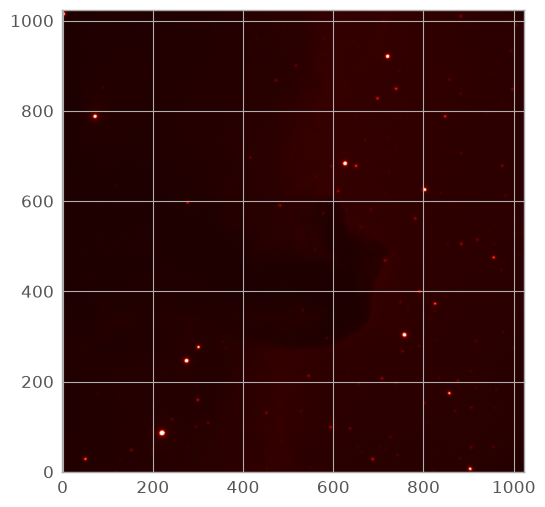

In [26]:
# Apply a square root scale to data visualization
plt.figure()
norm = simple_norm(data, 'sqrt')
plt.imshow(data, origin='lower', norm=norm)
plt.show()

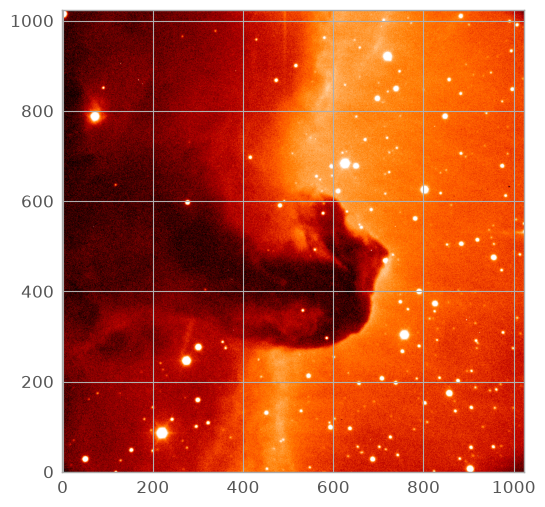

In [39]:
### ToDo: 
###  experiment w/ other scales: 'linear', 'sqrt', 'power', 'log', 'asinh'
###  set levels w/ parameters min_cut/max_cut or min_percent/max_percent

plt.figure()
norm = simple_norm(data, 'asinh', asinh_a=0.1, min_percent=1, max_percent=99.5)
plt.imshow(data, origin='lower', norm=norm)
plt.show()

Check __[simple_norm documentation](https://docs.astropy.org/en/stable/api/astropy.visualization.mpl_normalize.simple_norm.html#astropy.visualization.mpl_normalize.simple_norm)__

2578 64985


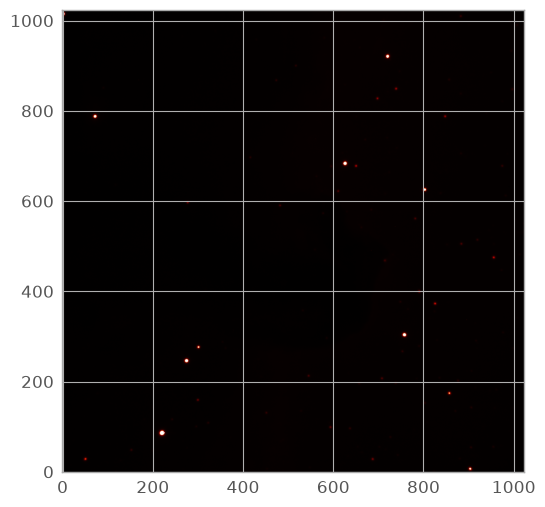

In [41]:
interval = MinMaxInterval()
z1, z2 = interval.get_limits(data)
print(z1, z2)
plt.figure()
im = plt.imshow(data, origin='lower', vmin=z1, vmax=z2)
plt.show()

2900 5000


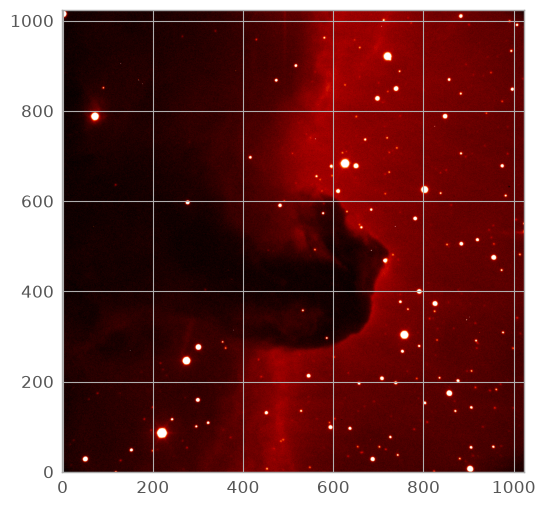

In [82]:
### ToDo: experiment w/ other available options: 
###  ManualInterval, PercentileInterval, AsymmetricPercentileInterval, and ZScaleInterval 
from astropy.visualization import (ManualInterval, PercentileInterval, AsymmetricPercentileInterval, ZScaleInterval)

interval = ManualInterval(2900,5000)
z1, z2 = interval.get_limits(data)
print(z1, z2)
plt.figure()
im = plt.imshow(data, origin='lower', vmin=z1, vmax=z2)
plt.show()

For more details see __[astropy.visualization documentation](https://docs.astropy.org/en/stable/visualization/normalization.html)__ 

## Compute and display statistics of a FITS image

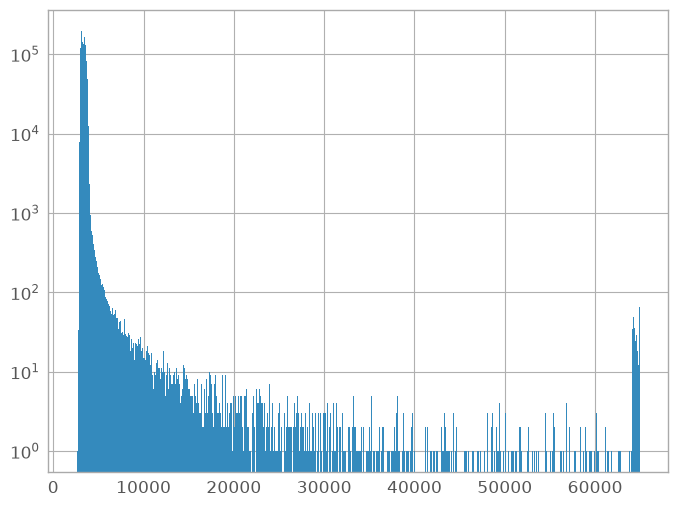

In [60]:
# load FITS image
hdul = pf.open('intro-iraf-files-2018-extracted/IC434R-001.fit')
# store the data in a variable
data = hdul[0].data
# plot data histogram w/ 100 bins using matplotlib's histogram
plt.figure()
plt.hist(data.ravel(), bins=550, log=True) # data.ravel() converts the image into a 1-D array
plt.show()
### ToDo: find the "best" number of bins

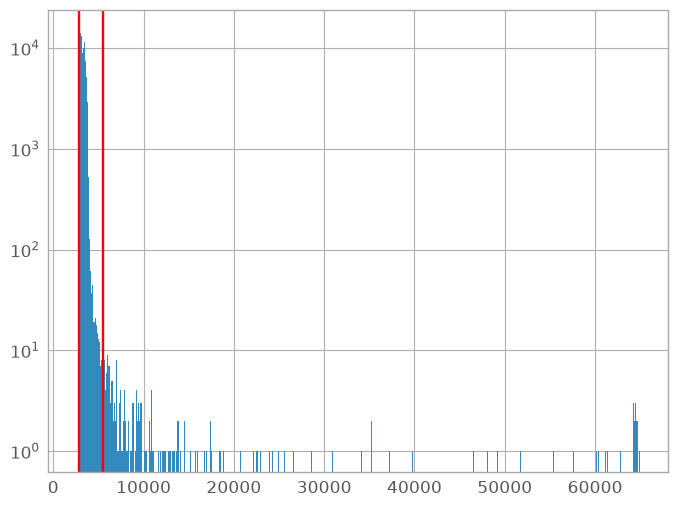

In [81]:
plt.figure()
hist(data.ravel(), bins='freedman', log=True) # options 'scott' and 'freedman' provide automatic determination of #bins
plt.axvline(2900, color='r')
plt.axvline(5500, color='r')
plt.show()